# Étape 2 — Apprentissage supervisé

**Instance** : les 11 variables explicatives du sujet + mois + année.
**Cible** : température à 2 m du **mois suivant**, discrétisée en **3 intervalles de même largeur**.
**Split** : chronologique.

Modèles : KNN, SVM, forêt aléatoire, AdaBoost, vote dur et vote souple.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)

In [2]:
from src import config as C
from src import supervised as sp

clean = pd.read_parquet(C.FILE_CLEAN)
print("features :", sp.FEATURES)

features : ['d2m', 'slhf', 'ssr', 'str', 'sshf', 'ro', 'e', 'u10', 'v10', 'sp', 'tp', 'year', 'month', 'month_sin', 'month_cos']


## 1. Décalage de la cible

`t2m` est décalée d'un mois **à l'intérieur de chaque point de grille**. Une vérification sur les dates écarte les cas où les deux mois ne se suivent pas (trou dans la série).

In [3]:
frame = sp.build_frame(clean)
frame.loc[:5, ["time", "latitude", "longitude", "t2m", "t2m_target"]]

[info supervisé] variables absentes ignorées : ['sshf']


,time,latitude,longitude,t2m,t2m_target
0,2015-01-01,19.05,3.25,15.980133,21.616119
1,2015-02-01,19.05,3.25,21.616119,23.896149
2,2015-03-01,19.05,3.25,23.896149,27.411774
3,2015-04-01,19.05,3.25,27.411774,33.287750
4,2015-05-01,19.05,3.25,33.287750,35.392242
5,2015-06-01,19.05,3.25,35.392242,34.376862


## 2. Split chronologique puis discrétisation équi-largeur

Les bornes sont calculées **sur le train seul** puis appliquées au test : les
calculer sur l'ensemble complet ferait fuir dans le train une information sur
l'étendue des températures futures. Les bornes extrêmes sont ouvertes (±∞) pour
absorber les valeurs de test hors étendue.

In [4]:
train, test, edges = sp.prepare(clean)

[info supervisé] variables absentes ignorées : ['sshf']
bornes équi-largeur (°C, calées sur le train) : [ 0.91 14.33 27.74 41.16]
split chronologique : train < 2025 (637,920 lignes) | test >= 2025 (106,320 lignes)
répartition des classes (train) :
classe
froid      0.178
tempere    0.433
chaud      0.389


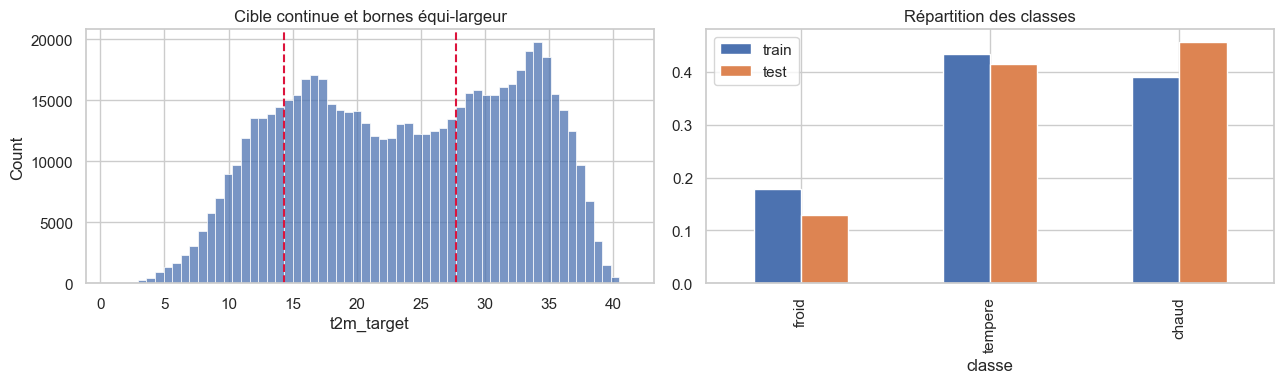

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(train["t2m_target"], bins=60, ax=axes[0])
for b in edges[1:-1]:
    axes[0].axvline(b, color="crimson", ls="--")
axes[0].set_title("Cible continue et bornes équi-largeur")

pd.concat([train["classe"].value_counts(normalize=True).rename("train"),
           test["classe"].value_counts(normalize=True).rename("test")], axis=1) \
  .reindex(C.BIN_LABELS).plot.bar(ax=axes[1], title="Répartition des classes")
plt.tight_layout();

## 3. Entraînement et comparaison

Tous les modèles sont entraînés sur le **même** sous-échantillon du train : le SVM est quadratique en nombre de lignes, et l'échantillon commun garde la comparaison à effectif égal. Mettre `sample_size=None` pour utiliser tout le train (long).

In [6]:
table, fitted, reports = sp.evaluate(train, test)
table.round(3)

[info] entraînement sur un sous-échantillon de 30,000 lignes sur 637,920 (coût du SVM ; comparaison à effectif égal)
  baseline       acc=0.414  f1_macro=0.195  (0.0s)
  knn            acc=0.828  f1_macro=0.809  (0.2s)
  svm            acc=0.861  f1_macro=0.834  (15.3s)
  random_forest  acc=0.885  f1_macro=0.863  (8.6s)
  adaboost       acc=0.876  f1_macro=0.852  (109.9s)
  vote_hard      acc=0.879  f1_macro=0.861  (34.9s)
  vote_soft      acc=0.884  f1_macro=0.866  (115.8s)


,modele,accuracy,balanced_acc,f1_macro,f1_pondere,kappa,temps_fit_s
0,vote_soft,0.884,0.869,0.866,0.884,0.808,115.8
1,random_forest,0.885,0.878,0.863,0.886,0.812,8.6
2,vote_hard,0.879,0.868,0.861,0.879,0.801,34.9
3,adaboost,0.876,0.864,0.852,0.876,0.796,109.9
4,svm,0.861,0.832,0.834,0.861,0.769,15.3
5,knn,0.828,0.826,0.809,0.826,0.717,0.2
6,baseline,0.414,0.333,0.195,0.242,0.000,0.0


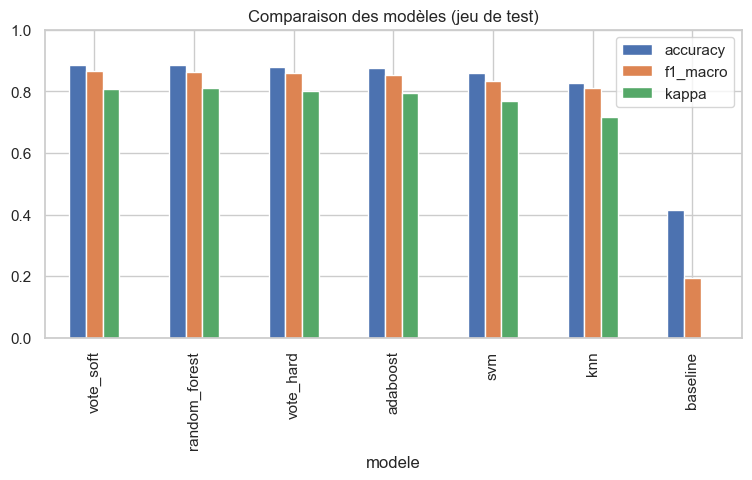

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
table.set_index("modele")[["accuracy", "f1_macro", "kappa"]].plot.bar(ax=ax)
ax.set_title("Comparaison des modèles (jeu de test)")
ax.set_ylim(0, 1);

## 4. Analyse du meilleur modèle

In [8]:
best = table.loc[0, "modele"]
print(f"=== {best} ===")
print(reports[best]["report"])

=== vote_soft ===
              precision    recall  f1-score   support

       froid       0.80      0.82      0.81     13731
     tempere       0.86      0.85      0.86     43988
       chaud       0.93      0.93      0.93     48601

    accuracy                           0.88    106320
   macro avg       0.86      0.87      0.87    106320
weighted avg       0.88      0.88      0.88    106320



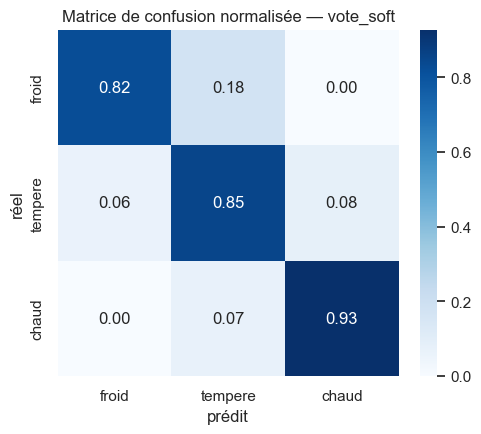

In [9]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
cm = pd.DataFrame(reports[best]["confusion"], index=C.BIN_LABELS, columns=C.BIN_LABELS)
sns.heatmap(cm / cm.sum(axis=1).values[:, None], annot=True, fmt=".2f", cmap="Blues", ax=ax)
ax.set(xlabel="prédit", ylabel="réel", title=f"Matrice de confusion normalisée — {best}");

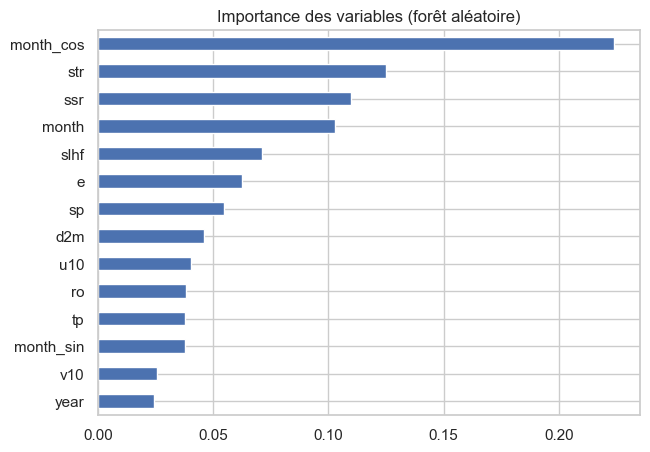

In [10]:
rf = fitted["random_forest"]
pd.Series(rf.feature_importances_, index=sp.FEATURES).sort_values().plot.barh(
    figsize=(7, 5), title="Importance des variables (forêt aléatoire)");

## 5. Erreur dans le temps et dans l'espace

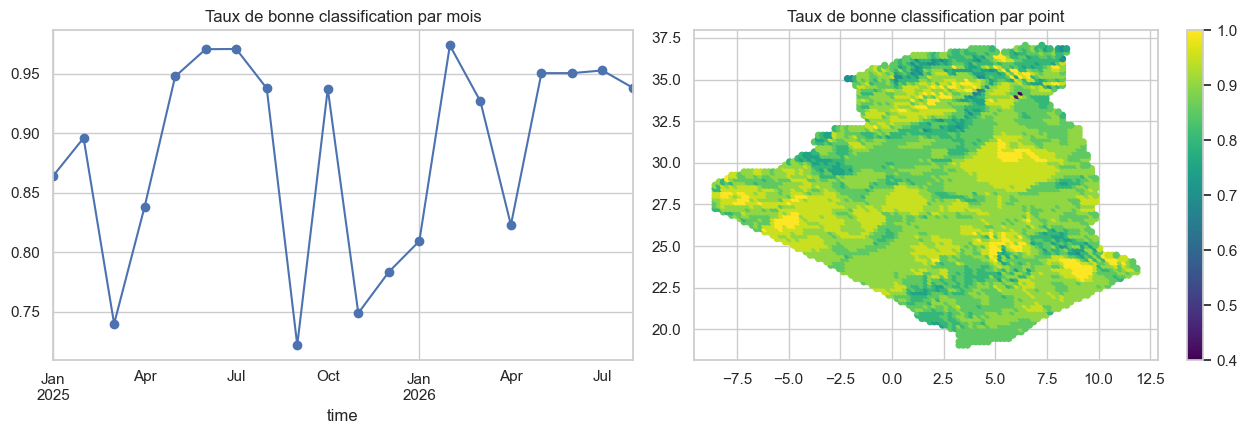

In [11]:
pred = fitted[best].predict(test[sp.FEATURES])
err = test.assign(juste=(pred == test["classe"]).astype(float))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
err.groupby("time")["juste"].mean().plot(ax=axes[0], marker="o",
                                         title="Taux de bonne classification par mois")
carte = err.groupby(["latitude", "longitude"])["juste"].mean().reset_index()
s = axes[1].scatter(carte["longitude"], carte["latitude"], c=carte["juste"],
                    cmap="viridis", s=18)
plt.colorbar(s, ax=axes[1])
axes[1].set_title("Taux de bonne classification par point")
plt.tight_layout();